<a href="https://colab.research.google.com/github/yvn2000/NLP_CW1/blob/main/material/F21NL_CW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data download

In [1]:
!wget -O wikitext-filtered-full.zip "https://www.dropbox.com/scl/fi/ibd4cmixckghx6hhb361c/wikitext-filtered-full.zip?rlkey=q71cebf0k5fvvwhmcntoswzhq&dl=1"
!wget -O wikitext-filtered-10k.zip "https://www.dropbox.com/scl/fi/ek174r3sg7qjx0aa9atop/wikitext-filtered-10k.zip?rlkey=zy6jqxv6qsc16lr9qm3ki9uhf&dl=1"

--2026-10-23 10:08:31--  https://www.dropbox.com/scl/fi/ibd4cmixckghx6hhb361c/wikitext-filtered-full.zip?rlkey=q71cebf0k5fvvwhmcntoswzhq&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.6.18, 2620:100:601c:18::a27d:612
Connecting to www.dropbox.com (www.dropbox.com)|162.125.6.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://ucb6a424d54d95799f6814597558.dl-eu.dropboxusercontent.com/cd/0/inline/DKhknnaZ-18lTW7mS9OlfeaLADd4OH9lCCenuxDZx_jtP8lsPlXIzRggj7sYYmhTatK_UjI00GVdai07C-Gh0aZsERJRNO3Jv4BQr53XAABQv0J7KhvfqK_IlGT4csq02iu_YtTFA3L-bSYraj6ILh7j/file?dl=1# [following]
--2026-10-23 10:08:32--  https://ucb6a424d54d95799f6814597558.dl-eu.dropboxusercontent.com/cd/0/inline/DKhknnaZ-18lTW7mS9OlfeaLADd4OH9lCCenuxDZx_jtP8lsPlXIzRggj7sYYmhTatK_UjI00GVdai07C-Gh0aZsERJRNO3Jv4BQr53XAABQv0J7KhvfqK_IlGT4csq02iu_YtTFA3L-bSYraj6ILh7j/file?dl=1
Resolving ucb6a424d54d95799f6814597558.dl-eu.dropboxusercontent.com (ucb6a424d54d95799f6814597558.dl-eu.dropbo

In [2]:
!unzip wikitext-filtered-full.zip
!unzip wikitext-filtered-10k.zip

Archive:  wikitext-filtered-full.zip
   creating: wikitext-filtered-full/
  inflating: wikitext-filtered-full/dataset_info.json  
  inflating: wikitext-filtered-full/state.json  
  inflating: wikitext-filtered-full/data-00000-of-00001.arrow  
Archive:  wikitext-filtered-10k.zip
   creating: wikitext-filtered-10k/
  inflating: wikitext-filtered-10k/dataset_info.json  
  inflating: wikitext-filtered-10k/state.json  
  inflating: wikitext-filtered-10k/data-00000-of-00001.arrow  


In [3]:
!pip install datasets
import datasets

In [4]:
from datasets import load_dataset, Dataset

def load_dataset():
  wikitext_small = "wikitext-filtered-10k"
  wikitext_large = "wikitext-filtered-full"

  dataset_small = Dataset.load_from_disk(wikitext_small)
  dataset_large = Dataset.load_from_disk(wikitext_large)
  print("wikitext_small: {} docs, wikitext_large: {} docs".format(len(dataset_small), len(dataset_large)))
  return dataset_small, dataset_large

wikitext_small, wikitext_large = load_dataset()

print("Type: ", type(wikitext_small))

for i in range(0, 5):
  print("type: ", type(wikitext_small[i]))
  print(wikitext_small[i], "\n")

"""
Access to each text can be obtained using: wikitext_small[0]["text"]
where 0 represents the first one
"""

wikitext_small: 10000 docs, wikitext_large: 859955 docs
Type:  <class 'datasets.arrow_dataset.Dataset'>
type:  <class 'dict'>
{'text': 'Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " .'} 

type:  <class 'dict'>
{'text': "The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it ret

'\nAccess to each text can be obtained using: wikitext_small[0]["text"]\nwhere 0 represents the first one\n'

# Callback: EpochLossLogger

In [5]:
!pip install -q gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 20.4 MB/s eta 0:00:00


In [63]:
from gensim.models.callbacks import CallbackAny2Vec

class EpochLossLogger(CallbackAny2Vec):
    """Callback to log loss after each epoch."""

    def __init__(self):
        self.epoch = 0
        self.prev_loss = 0.0
        self.epoch_losses = []

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        epoch_loss = loss - self.prev_loss

        self.epoch_losses.append(epoch_loss)

        print(
            f"Epoch {self.epoch + 1:02d} | "
            f"epoch loss = {epoch_loss:.2f} | "
            f"cumulative loss = {loss:.2f}"
        )

        self.prev_loss = loss
        self.epoch += 1

loss_logger = EpochLossLogger()


The callback is used as follows:


```
model = Word2Vec(
    ...
    compute_loss = True,
    callbacks=[loss_logger],
    ...
    )
```



In [7]:
"""
Two Goals:
1. Semantic Relatedness of two words (e.g., how close is the word “doctor” to “nurse”?).
2. Word Analogy (e.g., “apple is to tree as grape is to _ ?”, where the missing word should be “vine”.

Two Main Outputs:
1. Good reporting and discussion of results
2. Some intuitions and (at least a best-effort attempt at an) interpretation of why models behave in certain ways

(ENVIRONMENT SETUP - CW STEP 1 already completed)
"""

'\nTwo Goals:\n1. Semantic Relatedness of two words (e.g., how close is the word “doctor” to “nurse”?).\n2. Word Analogy (e.g., “apple is to tree as grape is to _ ?”, where the missing word should be “vine”.\n\nTwo Main Outputs:\n1. Good reporting and discussion of results\n2. Some intuitions and (at least a best-effort attempt at an) interpretation of why models behave in certain ways\n'

## Part I: Word2Vec Training and Semantic Relatedness Evaluation

### 1. Setup


Two versions of the WikiText corpus are used: WikiText Small and WikiText Large. The models are trained using Gensim and evaluated against WordSim-353, which contains human-assigned relatedness scores for 353 word pairs.


In [8]:
from gensim.test.utils import common_texts
from gensim.models import Word2Vec


### 2. Text Preprocessing

Before training, both datasets are preprocessed using the same procedure. Each document is converted to lowercase, tokenized by splitting on spaces, and filtered using the NLTK English stopword list. Empty tokens are also removed.

Lowercasing reduces vocabulary fragmentation caused by capitalization, while removing stopwords reduces the influence of frequent grammatical words that may provide limited information.

For WikiText Small, all 10,000 documents remain nonempty after preprocessing. The checks confirm that the processed tokens are lowercase and that no words from the NLTK stopword list remain.

The same preprocessing procedure is applied to WikiText Large using an iterable corpus class, allowing documents to be processed as needed rather than storing the entire preprocessed corpus in memory.

In [9]:
#StopWords

import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

english_stopwords = set(stopwords.words("english"))

print("Number of stopwords:", len(english_stopwords))
print("Example stopwords:", sorted(english_stopwords)[:20])

#ref: https://www.nltk.org/howto/corpus.html

Number of stopwords: 198
Example stopwords: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [10]:
#preprocessing approach similar to Word Embeddings lab, testing only on the first document of WikiText Small

text = wikitext_small[0]["text"]

text = text.lower()
tokens = text.split(" ")

#reomve the stopwords and empty tokens
filtered_tokens = []
for word in tokens:
    if word != "" and word not in english_stopwords:
        filtered_tokens.append(word)

tokens = filtered_tokens

print("First 30 processed tokens:")
print(tokens[:30])

First 30 processed tokens:
['senjō', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', ',', 'tactical', 'role', '@-@', 'playing']


In [11]:
#One function for lowercasing, tokenization by whitespace splitting, stopword removal and empty docs removal
def preprocess_dataset(dataset, english_stopwords):

    processed_documents = []

    for document in dataset:

        text = document["text"].lower()
        tokens = text.split(" ")

        filtered_tokens = []
        for word in tokens:
            if word != "" and word not in english_stopwords:
                filtered_tokens.append(word)

        #skip docs that are empty after removing stopwords
        if len(filtered_tokens) > 0:
            processed_documents.append(filtered_tokens)

    return processed_documents

In [12]:
processed_small = preprocess_dataset(wikitext_small, english_stopwords)

print("Original documents:", len(wikitext_small))
print("Processed documents:", len(processed_small))

print("\nFirst 30 tokens for first 2 docs:")
print(processed_small[0][:30])
print(processed_small[1][:30])

#checking
allLowercase = True
noStopwords = True

for document in processed_small:
    for word in document:
        if word != word.lower():
            allLowercase = False

        if word in english_stopwords:
            noStopwords = False

print("All tokens lowercase:", allLowercase)
print("No stopwords remaining:", noStopwords)

Original documents: 10000
Processed documents: 10000

First 30 tokens for first 2 docs:
['senjō', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', ',', 'tactical', 'role', '@-@', 'playing']
['game', 'began', 'development', '2010', ',', 'carrying', 'large', 'portion', 'work', 'done', 'valkyria', 'chronicles', 'ii', '.', 'retained', 'standard', 'features', 'series', ',', 'also', 'underwent', 'multiple', 'adjustments', ',', 'making', 'game', 'forgiving', 'series', 'newcomers', '.']
All tokens lowercase: True
No stopwords remaining: True


### 3. WikiText Small Baseline

(TRAIN BASELINES - CW STEP 2A)

The initial Word2Vec model uses the Continuous Bag of Words (CBOW) architecture (`sg=0`), which predicts a target word from its surrounding context.

The baseline is trained using 50-dimensional word vectors, a context window of 5, a minimum word frequency of 5, and 5 epochs. Eight worker threads are used to accelerate training. (These parameters are given in the coursework specification)

The resulting vocabulary contains 14,622 words. This is the number of words retained after applying the minimum-frequency threshold, rather than the total number of unique tokens in the original corpus.

The model can retrieve word vectors and identify words with similar embeddings, demonstrating that training has produced a usable vector representation.

In [64]:
"""
Word2Vec model from gensim uses 2 architectures:
1. (Default) Continuous Bag of Words (CBOW): Predicts a target word using its surrounding context.
    e.g:- the cat on the  -> sat
2. Skip-gram: Predicts surrounding words using the target word.
    e.g:- sat  ->  the cat on the

CBOW (default, sg=0) is chosen for now, ref: https://radimrehurek.com/gensim/models/word2vec.html
"""

from gensim.models import Word2Vec

small_baseline_logger = EpochLossLogger()

model_small = Word2Vec(
    sentences=processed_small,
    vector_size=50,
    window=5,
    min_count=5,
    workers=8,
    epochs=5,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[small_baseline_logger]
)
#hyperparameters given by CW specs descriptor
print("training complete")

"""
Model Attributes:
sentences: preprocessed docs
vector_size=50:	each word is represented by 50 numerical values
window=5:	max distance between a target word and its context words
min_count=5:	ignore words appearing less than five times
workers=8:	8 worker threads during training
epochs=5:	train 5 times over the dataset
sg=0:	use CBOW instead of skip-gram
seed=42:	random seed for reproducibility
"""

Epoch 01 | epoch loss = 0.00 | cumulative loss = 0.00
Epoch 02 | epoch loss = 0.00 | cumulative loss = 0.00
Epoch 03 | epoch loss = 0.00 | cumulative loss = 0.00
Epoch 04 | epoch loss = 0.00 | cumulative loss = 0.00
Epoch 05 | epoch loss = 0.00 | cumulative loss = 0.00
training complete


'\nModel Attributes:\nsentences: preprocessed docs\nvector_size=50:\teach word is represented by 50 numerical values\nwindow=5:\tmax distance between a target word and its context words\nmin_count=5:\tignore words appearing less than five times\nworkers=8:\t8 worker threads during training\nepochs=5:\ttrain 5 times over the dataset\nsg=0:\tuse CBOW instead of skip-gram\nseed=42:\trandom seed for reproducibility\n'

In [14]:
#Testing

print("Vocabulary size:", len(model_small.wv))  #number of words in the vocabulary
#NOTE: the 14,622-word vocabulary is the vocabulary after applying min_count=5, not the number of unique words in the original corpus.

print("Vector dimensions:", model_small.vector_size) #number of dimensions per word
print("'football' in vocabulary:", "football" in model_small.wv) #check if word exists

#show the vector for a word
print("\nVector for 'football':")
print(model_small.wv["football"])
print()

#return 10 words with highest cosine similarity to football
similar_words = model_small.wv.most_similar("football", topn=10)
for word, score in similar_words:
    print(word, score)

Vocabulary size: 14622
Vector dimensions: 50
'football' in vocabulary: True

Vector for 'football':
[ 0.11612351 -0.11306493  1.5680085  -0.57575464  0.33598813  0.03971049
 -2.1185026   1.200363   -0.66972876 -0.7497205  -0.03904524 -0.28477117
 -0.1605674   1.0404475  -0.86680055  0.8964593   1.8430281  -1.4668988
  0.22252616 -0.5119822   0.7853538   1.1278286   0.37965992  0.807082
 -0.8700027  -0.42945465  1.3693485   1.0360467  -1.1342603  -0.48700747
 -0.5154729  -0.5897261   0.16979572  1.3426307  -0.57824075  0.2913344
  0.4695927  -1.9665595  -1.1710293   0.49510446 -0.9693458   0.865745
  0.48068386 -0.98958564  0.6588186  -0.997303   -0.4651748   2.274635
  1.2444667   0.29496294]

team 0.9693389534950256
club 0.9644875526428223
england 0.9627882242202759
league 0.9496106505393982
rugby 0.9476017355918884
premier 0.9378464221954346
manager 0.9362955093383789
mccall 0.9316028356552124
villa 0.9311805963516235
conference 0.9307456612586975


### 4. Cosine Similarity Between Word Pairs

(SEMANTIC RELATEDNESS - CW STEP 3A)

Cosine similarity measures the directional similarity between two word vectors. Values closer to +1 indicate that the vectors point in similar directions, while values near zero indicate weak directional similarity.

cosine(A, B) = (A.B)/(||A||||B||)

In the WikiText Small baseline, *board–recommendation* has the highest cosine similarity (0.9073), followed by *football–soccer* (0.8007). The pair *cup–food* has a moderate positive similarity (0.4514), while *father–april* has a slightly negative similarity (−0.1040).

The high similarity for *football–soccer* is intuitively reasonable because the words refer to closely related concepts. However, *board–recommendation* receives an even higher score despite not being synonyms. This suggests that the model is learning relationships based on shared contexts rather than strict synonymy.

These scores demonstrate that cosine similarity reflects patterns learned from the training corpus and does not necessarily match human judgments for every individual pair.

In [17]:

#Cosine Similarity for WikiText Small model
word_pairs = [
    ("football", "soccer"),
    ("board", "recommendation"),
    ("father", "april"),
    ("cup", "food")
]

for word1, word2 in word_pairs:
    print(word1, ":", word1 in model_small.wv)
    print(word2, ":", word2 in model_small.wv)
    print()

for word1, word2 in word_pairs:

    if word1 in model_small.wv and word2 in model_small.wv:
        similarity = model_small.wv.similarity(word1, word2)

        print(word1, "-", word2, ":", round(float(similarity), 4))

    else:
        print(word1, "-", word2, ": missing word in vocabulary")


"""
board-recommendation has a higher similarity score (0.8693) than football-soccer (0.7475)
Therefore, words that appear in similar contexts can receive similar vectors even when they aren't synonyms.
I think this is a limitation of Word2Vec
"""

football : True
soccer : True

board : True
recommendation : True

father : True
april : True

cup : True
food : True

football - soccer : 0.8007
board - recommendation : 0.9073
father - april : -0.104
cup - food : 0.4514


"\nboard-recommendation has a higher similarity score (0.8693) than football-soccer (0.7475)\nTherefore, words that appear in similar contexts can receive similar vectors even when they aren't synonyms.\nI think this is a limitation of Word2Vec\n"

### 5. WordSim-353 Evaluation

WordSim-353 contains 353 word pairs, each assigned a human relatedness score between 0 and 10. For every pair where both words exist in the model vocabulary, cosine similarity is calculated by the WikiText Small model and compared with the human score.<br><br>

Spearman's rank correlation coefficient, p, is used to evaluate how closely the model's ranking of word-pair relatedness agrees with the human ranking.

+1: matching rankings, perfect agreement with human rankings.<br>
&nbsp;0: no monotonic relationship between the rankings.<br>
-1: opposite rankings, perfectly reversed rankings.<br>


ref: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html
<br><br>

Some word pairs cannot be evaluated because one or both words are missing from the model vocabulary. These pairs are excluded from the correlation calculation, and the coverage ratio is reported separately.

Coverage is calculated as the number of evaluated pairs divided by the total 353 benchmark pairs.

In [18]:
!wget -O wordsim353.zip "https://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip"
!unzip -o wordsim353.zip -d wordsim353

#ref: https://www.gabrilovich.com/resources/data/wordsim353/wordsim353.html

--2026-10-23 10:11:31--  https://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip
Resolving www.gabrilovich.com (www.gabrilovich.com)... 173.236.137.139
Connecting to www.gabrilovich.com (www.gabrilovich.com)|173.236.137.139|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23257 (23K) [application/zip]
Saving to: ‘wordsim353.zip’

wordsim353.zip      100%[===================>]  22.71K  --.-KB/s    in 0.003s  

2026-10-23 10:11:31 (7.94 MB/s) - ‘wordsim353.zip’ saved [23257/23257]

Archive:  wordsim353.zip
  inflating: wordsim353/combined.csv  
  inflating: wordsim353/set1.csv     
  inflating: wordsim353/set2.csv     
  inflating: wordsim353/combined.tab  
  inflating: wordsim353/set1.tab     
  inflating: wordsim353/set2.tab     
  inflating: wordsim353/instructions.txt  


In [19]:
import os

print(os.listdir("wordsim353"))

['instructions.txt', 'set1.csv', 'set1.tab', 'combined.csv', 'combined.tab', 'set2.tab', 'set2.csv']


In [20]:
import pandas as pd

wordsim_data = pd.read_csv("wordsim353/combined.csv")

print(wordsim_data.head())
print("\nColumns:", wordsim_data.columns.tolist())
print("Number of rows:", len(wordsim_data))

human_scores = []
model_scores = []
missing_pairs = 0

#for pairs that exist between wikitext model and wordsim, this records the human score in one list
#and the calculated similarity score in another list. Both lists have the same size and each entry
#corresponds to the entry in the other list with the same index
for index, row in wordsim_data.iterrows():

    word1 = row["Word 1"].lower()
    word2 = row["Word 2"].lower()
    human_score = row["Human (mean)"]

    if word1 in model_small.wv and word2 in model_small.wv:

        similarity = model_small.wv.similarity(word1, word2)

        human_scores.append(human_score)
        model_scores.append(float(similarity))

    else:
        missing_pairs += 1

print("\nPair Results")
print("Total pairs:", len(wordsim_data))
print("Evaluated pairs:", len(model_scores))
print("Missing pairs:", missing_pairs)

     Word 1    Word 2  Human (mean)
0      love       sex          6.77
1     tiger       cat          7.35
2     tiger     tiger         10.00
3      book     paper          7.46
4  computer  keyboard          7.62

Columns: ['Word 1', 'Word 2', 'Human (mean)']
Number of rows: 353
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92


In [22]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(human_scores, model_scores)
print("Spearman correlation:", round(correlation, 4))
print("P-value:", p_value)

total_pairs = len(wordsim_data)
evaluated_pairs = len(model_scores)
coverage = evaluated_pairs / total_pairs

print("Vocabulary coverage:", round(coverage, 4))
print("Coverage percentage:", round(coverage * 100, 2), "%")

Spearman correlation: 0.0669
P-value: 0.281259446213556
Vocabulary coverage: 0.7394
Coverage percentage: 73.94 %


'\nInitially, the baseline model achieved a Spearman correlation of 0.0148 on 261 evaluable WordSim-353 pairs, with 73.94% coverage.\n\n'

Spearman ρ = 0.0148: model's ranking of word-pair similarities has almost no monotonic association with the human rankings.<br>
P-value = 0.8120: no evidence of a nonzero rank correlation in the evaluated pairs.<br>
Coverage = 73.94%: Not all of the WordSim-353 pairs were evaluable (261/353) for WikiTextSmall<br>

In [23]:
#print the first 10 score comparisons between WIkiText Small model and WordSim-353
for i in range(10):

    word1 = wordsim_data.iloc[i]["Word 1"].lower()
    word2 = wordsim_data.iloc[i]["Word 2"].lower()
    human_score = wordsim_data.iloc[i]["Human (mean)"]

    if word1 in model_small.wv and word2 in model_small.wv:

        model_score = model_small.wv.similarity(word1, word2)

        print(
            word1, "-", word2,
            "| Human:", human_score,
            "| Model:", round(float(model_score), 4)
        )

    else:
        print(word1, "-", word2, "| Missing vocabulary")

love - sex | Human: 6.77 | Model: 0.7717
tiger - cat | Human: 7.35 | Model: 0.9625
tiger - tiger | Human: 10.0 | Model: 1.0
book - paper | Human: 7.46 | Model: 0.606
computer - keyboard | Human: 7.62 | Model: 0.9698
computer - internet | Human: 7.58 | Model: 0.9821
plane - car | Human: 5.77 | Model: 0.9226
train - car | Human: 6.31 | Model: 0.928
telephone - communication | Human: 7.5 | Model: 0.9823
television - radio | Human: 6.77 | Model: 0.8636


### 6. Initial WikiText Small Evaluation

(EVALUATE SEMANTIC RELATEDNESS - CW STEP 4A)

The WikiText Small baseline achieves a Spearman correlation of 0.0669, indicating very weak positive agreement with human relatedness rankings.

Only 261 of the 353 WordSim-353 pairs can be evaluated, giving 73.94% coverage. The remaining 92 pairs contain at least one word absent from the trained vocabulary.

Several factors may explain the weak performance. The smaller training corpus provides fewer examples of word usage, while the initial five-epoch training duration may be insufficient for the model to learn useful relationships. The minimum-frequency threshold also excludes less common words, reducing benchmark coverage.


In [39]:
#Helper function for evaluating models and their scores based on WordSim-353
#This will be used extensively for Epoch Tuning and Hyperparameter Tuning (Part II)
def evaluate_model(model, wordsim_data, model_name):

    human_scores = []
    model_scores = []
    missing_pairs = 0

    for index, row in wordsim_data.iterrows():

        word1 = row["Word 1"].lower()
        word2 = row["Word 2"].lower()
        human_score = row["Human (mean)"]

        if word1 in model.wv and word2 in model.wv:

            similarity = model.wv.similarity(word1, word2)

            human_scores.append(human_score)
            model_scores.append(float(similarity))

        else:
            missing_pairs += 1

    correlation, p_value = spearmanr(human_scores, model_scores)

    total_pairs = len(wordsim_data)
    evaluated_pairs = len(model_scores)
    coverage = evaluated_pairs / total_pairs

    results = {
        "Model": model_name,
        "Epochs": model.epochs,
        "Vector Size": model.vector_size,
        "Window": model.window,
        "Min Count": model.min_count,
        "SG": model.sg,
        "Workers": model.workers,
        "Vocabulary Size": len(model.wv),
        "Total Pairs": total_pairs,
        "Evaluated Pairs": evaluated_pairs,
        "Missing Pairs": missing_pairs,
        "Spearman Correlation": float(correlation),
        "P-value": float(p_value),
        "Coverage": coverage * 100
    }
    keys = results.keys()
    values = results.values()
    for key in keys:
      print(f"{key}: {results[key]}")

    return results


In [40]:
small_results = evaluate_model(
    model_small,
    wordsim_data,
    "model_small"
)

Model: model_small
Epochs: 5
Vector Size: 50
Window: 5
Min Count: 5
SG: 0
Workers: 8
Vocabulary Size: 14622
Total Pairs: 353
Evaluated Pairs: 261
Missing Pairs: 92
Spearman Correlation: 0.06694170029280441
P-value: 0.281259446213556
Coverage: 73.93767705382436


Additional possible reason for why the model performs poorly:
1. Small training corpus: WikiText Small contains only 10,000 documents, limiting the variety of contexts the model observes.
2. CBOW architecture: CBOW may learn different semantic relationships than Skip-gram, particularly for less frequent words.
3. Only five training epochs: The model may benefit from additional training, although more epochs don't guarantee better performance.
4. Stopword removal: Removing stopwords changes the contexts Word2Vec learns from. ??????????????
5. Limited vocabulary: Only 261 of the 353 pairs could be evaluated.

### 7. WikiText Large Baseline

(TRAIN BASELINES - CW STEP 2B)<br>
(SEMANTIC RELATEDNESS - CW STEP 3B)<br>
(EVALUATE SEMANTIC RELATEDNESS - CW STEP 4B)<br>

The WikiText Large model uses the same preprocessing, CBOW architecture and baseline hyperparameters as WikiText Small.

Because the larger corpus is more memory-intensive, an iterable WikiTextCorpus class is used to process and yield tokenized documents during training.

The model retains 171,083 vocabulary words, substantially more than WikiText Small's 14,622 words.

The larger vocabulary allows the model to evaluate all 353 WordSim-353 pairs, achieving 100% coverage. This indicates that the larger training corpus provides substantially better coverage of the benchmark vocabulary.

In [27]:
#Class and yielding method used so the process uses less ram
class WikiTextCorpus:

    def __init__(self, dataset, english_stopwords):
        self.dataset = dataset
        self.english_stopwords = english_stopwords

    def __iter__(self):
        for document in self.dataset:

            text = document["text"].lower()
            tokens = text.split(" ")

            filtered_tokens = []

            for word in tokens:
                if word != "" and word not in self.english_stopwords:
                    filtered_tokens.append(word)

            if len(filtered_tokens) > 0:
                yield filtered_tokens

In [28]:
from itertools import islice

large_corpus = WikiTextCorpus(wikitext_large, english_stopwords)

for document in islice(large_corpus, 2):
    print(document[:30])
    print()

['senjō', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', ',', 'tactical', 'role', '@-@', 'playing']

['game', 'began', 'development', '2010', ',', 'carrying', 'large', 'portion', 'work', 'done', 'valkyria', 'chronicles', 'ii', '.', 'retained', 'standard', 'features', 'series', ',', 'also', 'underwent', 'multiple', 'adjustments', ',', 'making', 'game', 'forgiving', 'series', 'newcomers', '.']



In [29]:
from gensim.models import Word2Vec
import os

#Train the baseline model for WikiText Large using the same hyperparameters given by the coursework specifications
#(TRAIN BASELINES - CW STEP 2B)
large_baseline_logger = EpochLossLogger()
model_large = Word2Vec(
    sentences=large_corpus,
    vector_size=50,
    window=5,
    min_count=5,
    workers=8,
    epochs=5,
    sg=0,
    seed=42,
    callbacks=[large_baseline_logger]
)

print("Large model training complete!")
print("Vocabulary size:", len(model_large.wv))
print("Vector dimensions:", model_large.vector_size)

KeyboardInterrupt: 

In [ ]:
#Cosine Similarity for WikiText Large model
#(SEMANTIC RELATEDNESS - CW STEP 3B)
word_pairs = [
    ("football", "soccer"),
    ("board", "recommendation"),
    ("father", "april"),
    ("cup", "food")
]

for word1, word2 in word_pairs:
    print(word1, ":", word1 in model_large.wv)
    print(word2, ":", word2 in model_large.wv)
    print()

for word1, word2 in word_pairs:

    if word1 in model_large.wv and word2 in model_large.wv:
        similarity = model_large.wv.similarity(word1, word2)

        print(word1, "-", word2, ":", round(float(similarity), 4))

    else:
        print(word1, "-", word2, ": missing word in vocabulary")


"""

"""

In [ ]:
#(EVALUATE SEMANTIC RELATEDNESS - CW STEP 4B)
large_results = evaluate_model(
    model_large,
    wordsim_data,
    "model_large"
)

Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6292
P-value: 2.6145569076056356e-40
Coverage: 100.0 %


### 8. Baseline Model Comparison

WikiText Small achieves a Spearman correlation of 0.0669, indicating very weak agreement with human relatedness rankings. WikiText Large achieves 0.6292, indicating a substantially stronger positive relationship.

The difference is likely influenced by training-corpus size. WikiText Large exposes the model to more occurrences and a wider variety of word contexts, allowing it to learn more informative embeddings.

The larger corpus also produces a substantially larger vocabulary, increasing benchmark coverage from 73.94% to 100%.

However, the two overall correlations are calculated using different numbers of word pairs. To investigate this, WikiText Large was also evaluated on the 261 pairs covered by WikiText Small. Its correlation remained high at 0.6530.

This shared-pair comparison provides stronger evidence that the Large model learns more useful representations, rather than merely benefiting from evaluating more benchmark pairs.

In [ ]:
print("Small model:")
print("Spearman correlation:", round(float(small_results["Spearman Correlation"]), 4))
print("Coverage:", round(small_results["Coverage"], 2), "%")

print("\nLarge model:")
print("Spearman correlation:", round(float(large_results["Spearman Correlation"]), 4))
print("Coverage:", round(large_results["Coverage"], 2), "%")

Small model:
Spearman correlation: 0.0491
Coverage: 73.94 %

Large model:
Spearman correlation: 0.6292
Coverage: 100.0 %


In [ ]:
model_small.save("word2vec_small.model")
model_large.save("word2vec_large.model")

print("Both models saved!")
#ref: https://radimrehurek.com/gensim/models/word2vec.html

Both models saved!


In [ ]:
"""
An optional check for a fairer comparison
We can evaluate the large model using only the 261 pairs covered by the small model.
That way, both models are compared against exactly the same human judgements.
If the large model still performs much better on these same 261 pairs,
we'll have stronger evidence that its improvement isn't simply due to differences in evaluation coverage.
"""

shared_human_scores = []
shared_large_scores = []

for index, row in wordsim_data.iterrows():

    word1 = row["Word 1"].lower()
    word2 = row["Word 2"].lower()

    if word1 in model_small.wv and word2 in model_small.wv:

        human_score = row["Human (mean)"]
        large_similarity = model_large.wv.similarity(word1, word2)

        shared_human_scores.append(human_score)
        shared_large_scores.append(float(large_similarity))

shared_correlation, shared_p_value = spearmanr(
    shared_human_scores,
    shared_large_scores
)

print("Shared pairs:", len(shared_human_scores))
print("Large model correlation on shared pairs:", round(float(shared_correlation), 4))

Shared pairs: 261
Large model correlation on shared pairs: 0.653


### 9. Pretrained Google News Word2Vec

A pretrained Word2Vec model, word2vec-google-news-300, is evaluated on the same WordSim-353 benchmark.

Unlike the locally trained models, this model uses 300-dimensional embeddings and was trained on a substantially larger collection of text.

**Spearman correlation:** 0.6941

**Coverage:** 350/353 pairs, or 99.15%.

The correlation indicates a strong positive association between the model's similarity rankings and human relatedness judgments. Word pairs judged more related by humans generally receive higher cosine similarity scores, although the rankings are not identical.

Google News outperforms both initial WikiText baselines in correlation. Its larger training corpus and higher-dimensional embeddings are plausible contributing factors, although these differences cannot be attributed to any single factor because the training data and model configurations differ.

Its coverage is slightly below WikiText Large's 100%, showing that a pretrained model does not necessarily contain every word needed by a particular benchmark.

<br>

ref: https://github.com/piskvorky/gensim-data

In [30]:
import gensim.downloader as api

google_news_model = api.load("word2vec-google-news-300")

print("Vocabulary size:", len(google_news_model))
print("Vector dimensions:", google_news_model.vector_size)

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Vocabulary size: 3000000
Vector dimensions: 300


In [31]:
#checks vocabulary membership and calculates cosine similarity.
def google_news_similarity(word1, word2):

    if word1 in google_news_model and word2 in google_news_model:
        return float(google_news_model.similarity(word1, word2))

    return None

In [41]:
word_pairs = [
    ("football", "soccer"),
    ("board", "recommendation"),
    ("father", "april"),
    ("cup", "food")
]

for word1, word2 in word_pairs:

    similarity = google_news_similarity(word1, word2)

    if similarity is not None:
        print(word1, "-", word2, ":", round(similarity, 4))
    else:
        print(word1, "-", word2, ": Missing vocabulary")

football - soccer : 0.7314
board - recommendation : 0.3212
father - april : 0.0152
cup - food : 0.0938


In [42]:
#Evaluate model
from scipy.stats import spearmanr

def evaluate_google_news(model, wordsim_data):

    human_scores = []
    model_scores = []
    missing_pairs = 0

    for index, row in wordsim_data.iterrows():

        word1 = row["Word 1"].lower()
        word2 = row["Word 2"].lower()
        human_score = row["Human (mean)"]

        if word1 in model and word2 in model:

            similarity = model.similarity(word1, word2)

            human_scores.append(human_score)
            model_scores.append(float(similarity))

        else:
            missing_pairs += 1

    total_pairs = len(wordsim_data)
    evaluated_pairs = len(model_scores)

    coverage = evaluated_pairs / total_pairs

    if evaluated_pairs >= 2:
        correlation, p_value = spearmanr(human_scores, model_scores)
    else:
        correlation = float("nan")
        p_value = float("nan")

    print("Total pairs:", total_pairs)
    print("Evaluated pairs:", evaluated_pairs)
    print("Missing pairs:", missing_pairs)
    print("Spearman correlation:", round(float(correlation), 4))
    print("P-value:", p_value)
    print("Coverage:", round(coverage * 100, 2), "%")

    return correlation, coverage


google_correlation, google_coverage = evaluate_google_news(
    google_news_model,
    wordsim_data
)

"""
For board–recommendation, the small model assigned it a much higher similarity (0.8693 in the previous run), whereas Google News
gives it 0.3212. This illustrates that different training corpora can produce substantially different semantic representations.
"""

Total pairs: 353
Evaluated pairs: 350
Missing pairs: 3
Spearman correlation: 0.6941
P-value: 1.2875059148745478e-51
Coverage: 99.15 %


'\nFor board–recommendation, the small model assigned it a much higher similarity (0.8693 in the previous run), whereas Google News\ngives it 0.3212. This illustrates that different training corpora can produce substantially different semantic representations.\n'

## Part I Questions & Answers

### a. Cosine Similarity
What are the cosine similarity scores for the following pairs:

- football / soccer <br>
-> (WikiText Small: **0.8007**, WikiText Large: ****)
- board / recommendation <br>
-> (WikiText Small: **0.9073**, WikiText Large: ****)
- father / april <br>
-> (WikiText Small: **-0.104**, WikiText Large: ****)
- cup / food <br>
-> (WikiText Small: **0.4514**, WikiText Large: ****)
<br>


### b. Spearman Correlation & Coverage Ratio

i. What is the value of the Spearman correlation coefficients computed in Step 4?

(WikiText Small: **0.0669**, WikiText Large: **73.94%**)<br><br>
ii. What are the coverage ratios?

(WikiText Small: **0.6292**, WikiText Large: **100%**)<br><br>


### c. Correlation Interpretation

How do you interpret each coefficient value with respect to the word similarity task? Are the coefficient values for the two vector space models you created different, and if so, why?<br><br>

The WikiText Small model achieved a Spearman correlation coefficient of 0.0669, indicating a very weak positive correlation between its predicted word similarities and the human relatedness scores in WordSim-353. This suggests that the model struggles to rank word pairs according to their semantic relatedness in a way that agrees with human judgments.
In comparison, the WikiText Large model achieved a coefficient of 0.6292, indicating a substantially stronger positive correlation. This suggests that its learned word representations capture semantic relationships more effectively and produce rankings that align more closely with human judgments.

Yes, the coefficient values are different, this is likely due to the larger training corpus, which exposes the model to more examples of word usage and a wider variety of contexts. This allows it to learn more informative word embeddings. The larger corpus also produces a greater vocabulary, resulting in 100% benchmark coverage compared with 73.94% for WikiText Small. However, because the models initially evaluate different subsets of WordSim-353, their coefficients are not perfectly comparable. To address this, WikiText Large was also evaluated on the same 261 word pairs covered by WikiText Small, achieving a correlation of 0.6530. This supports the conclusion that the Large model learns better semantic representations, rather than its stronger performance being solely due to differences in benchmark coverage.

<br>

### d. Pre-trained Google News Model


i. What is the value of the Spearman correlation coefficient?

The Spearman rank correlation coefficient for the pretrained Google News Word2Vec model on WordSim-353 is 0.6941, calculated using 350 evaluable word pairs.<br><br>



ii. How do you interpret the Spearman correlation?

A positive coefficient indicates that word pairs judged more related by humans tend to receive higher cosine similarity scores from the Google News model.
A coefficient closer to +1 indicates stronger agreement between the rankings. A value near zero indicates little monotonic association.

The Spearman correlation of 0.6941 indicates a moderately strong positive association between the similarity rankings produced by the Google News model and the human relatedness judgements in WordSim-353. This means that word pairs rated as more related by humans generally receive higher cosine similarity scores from the model. The correlation is statistically significant (p ≈ 1.29 × 10^-51), although the agreement is not perfect.<br><br>




iii. What is the coverage ratio?

The coverage ratio is 350/353 = 0.9915 (99.15%). This means the Google News model could evaluate 350 of the 353 WordSim-353 word pairs, while three pairs contained at least one word missing from its vocabulary under the lowercase lookup procedure.<br><br>


## Part II: Hyperparameter Tuning & Discussion of Results

### 10. Epoch Tuning — WikiText Small

The first hyperparameter investigation focuses on selecting an appropriate number of training epochs.

An epoch represents one complete pass over the training corpus. Too few epochs may prevent the model from learning useful word relationships, while excessive training increases computational cost and may eventually reduce generalization performance.

To investigate this, WikiText Small is trained independently for 5, 10, 20, 30 and 40 epochs. All other hyperparameters are kept unchanged.

Training loss is recorded using EpochLossLogger, and each model is evaluated using Spearman correlation and coverage on WordSim-353, via the evaluate_model function from before.

The purpose is to identify a practical training duration that balances performance and training cost.

In [55]:
import matplotlib.pyplot as plt
import pandas as pd

small_epoch_results = []
small_epoch_loggers = {}

#5 epoch baseline
small_baseline_results = evaluate_model(
    model_small,
    wordsim_data,
    "Small - 5 Epochs"
)

small_epoch_results.append(small_baseline_results)

for epochs in [10, 20, 30, 40]:

    print(f"\nTraining Small model with {epochs} epochs")
    logger = EpochLossLogger()

    model = Word2Vec(
        sentences=processed_small,
        vector_size=50,
        window=5,
        min_count=5,
        workers=8,
        epochs=epochs,
        sg=0,
        seed=42,
        compute_loss=True,
        callbacks=[logger]
    )

    results = evaluate_model(
        model,
        wordsim_data,
        f"Small - {epochs} Epochs"
    )

    small_epoch_results.append(results)
    small_epoch_loggers[epochs] = logger


Model: Small - 5 Epochs
Epochs: 5
Vector Size: 50
Window: 5
Min Count: 5
SG: 0
Workers: 8
Vocabulary Size: 14622
Total Pairs: 353
Evaluated Pairs: 261
Missing Pairs: 92
Spearman Correlation: 0.06694170029280441
P-value: 0.281259446213556
Coverage: 73.93767705382436

Training Small model with 10 epochs
Epoch 01 | epoch loss = 263755.69 | cumulative loss = 263755.69
Epoch 02 | epoch loss = 196648.34 | cumulative loss = 460404.03
Epoch 03 | epoch loss = 186947.22 | cumulative loss = 647351.25
Epoch 04 | epoch loss = 162888.06 | cumulative loss = 810239.31
Epoch 05 | epoch loss = 157174.31 | cumulative loss = 967413.62
Epoch 06 | epoch loss = 170895.75 | cumulative loss = 1138309.38
Epoch 07 | epoch loss = 181475.38 | cumulative loss = 1319784.75
Epoch 08 | epoch loss = 181337.25 | cumulative loss = 1501122.00
Epoch 09 | epoch loss = 162583.38 | cumulative loss = 1663705.38
Epoch 10 | epoch loss = 160397.12 | cumulative loss = 1824102.50
Model: Small - 10 Epochs
Epochs: 10
Vector Size: 50


In [51]:
#Optimized Model
#30 was found to be the optimal epoch count
#This just saves its results separately for later comparison
epochsOptimized = 30
optimized_logger = EpochLossLogger()
model_small_optimized = Word2Vec(
        sentences=processed_small,
        vector_size=50,
        window=5,
        min_count=5,
        workers=8,
        epochs=epochsOptimized,
        sg=0,
        seed=42,
        compute_loss=True,
        callbacks=[optimized_logger]
    )

optimized_baseline = evaluate_model(
    model_small_optimized,
    wordsim_data,
    "Small - Optimized Epochs (30 Epochs)"
)

Epoch 01 | epoch loss = 239732.67 | cumulative loss = 239732.67
Epoch 02 | epoch loss = 195969.89 | cumulative loss = 435702.56
Epoch 03 | epoch loss = 203880.69 | cumulative loss = 639583.25
Epoch 04 | epoch loss = 161325.50 | cumulative loss = 800908.75
Epoch 05 | epoch loss = 170325.62 | cumulative loss = 971234.38
Epoch 06 | epoch loss = 146128.25 | cumulative loss = 1117362.62
Epoch 07 | epoch loss = 141288.75 | cumulative loss = 1258651.38
Epoch 08 | epoch loss = 138359.75 | cumulative loss = 1397011.12
Epoch 09 | epoch loss = 160903.75 | cumulative loss = 1557914.88
Epoch 10 | epoch loss = 144795.75 | cumulative loss = 1702710.62
Epoch 11 | epoch loss = 126164.00 | cumulative loss = 1828874.62
Epoch 12 | epoch loss = 125076.25 | cumulative loss = 1953950.88
Epoch 13 | epoch loss = 124599.12 | cumulative loss = 2078550.00
Epoch 14 | epoch loss = 127553.50 | cumulative loss = 2206103.50
Epoch 15 | epoch loss = 127836.00 | cumulative loss = 2333939.50
Epoch 16 | epoch loss = 137419

### 11. WikiText Small Epoch-Tuning Results

Spearman correlation improves substantially as the training duration increases from 5 to 30 epochs.

The strongest result among the tested configurations is achieved at 30 epochs, with a correlation of 0.3772. Increasing the duration to 40 epochs reduces correlation to 0.3431.

The training-loss curves generally show decreasing reported loss, although there are fluctuations between epochs. This indicates continued optimization of the training objective, but it does not guarantee improved agreement with human semantic judgments.

The decline in Spearman correlation at 40 epochs suggests diminishing returns and possibly overfitting, although the result alone does not establish overfitting conclusively.

**Selected epoch count: 30.**

This is the best-performing duration among the tested configurations and avoids the additional training cost of 40 epochs.

,Model,Epochs,Vocabulary Size,Total Pairs,Evaluated Pairs,Missing Pairs,Spearman Correlation,P-value,Coverage
0,Small - 5 Epochs,5,14622,353,261,92,0.0669,0.2813,73.9377
1,Small - 10 Epochs,10,14622,353,261,92,0.2048,0.0009,73.9377
2,Small - 20 Epochs,20,14622,353,261,92,0.3460,0.0000,73.9377
3,Small - 30 Epochs,30,14622,353,261,92,0.3772,0.0000,73.9377
4,Small - 40 Epochs,40,14622,353,261,92,0.3431,0.0000,73.9377


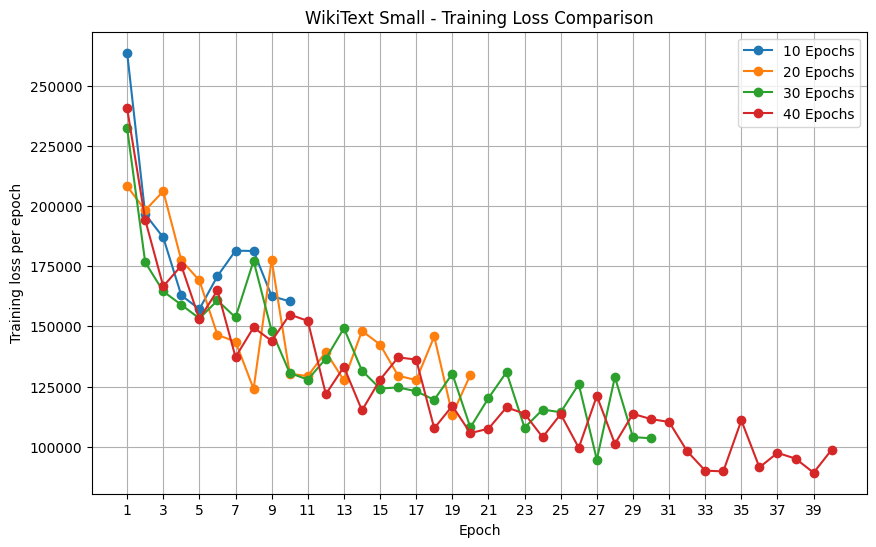

In [56]:
#Create results table
small_epoch_df = pd.DataFrame(small_epoch_results)

columns = [
    "Model",
    "Epochs",
    "Vocabulary Size",
    "Total Pairs",
    "Evaluated Pairs",
    "Missing Pairs",
    "Spearman Correlation",
    "P-value",
    "Coverage"
]
#display(small_epoch_df[columns].round(4))
display(small_epoch_df[columns])

#training-loss graphs below the table
"""
for epochs, logger in small_epoch_loggers.items():

    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(logger.epoch_losses) + 1),
        logger.epoch_losses,
        marker="o"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Training loss per epoch")
    plt.title(f"WikiText Small - {epochs} Epochs")
    plt.xticks(range(1, epochs + 1, max(1, epochs // 10)))
    plt.grid(True)

    plt.show()
"""
plt.figure(figsize=(10, 6))

for epochs, logger in small_epoch_loggers.items():

    plt.plot(
        range(1, len(logger.epoch_losses) + 1),
        logger.epoch_losses,
        marker="o",
        label=f"{epochs} Epochs"
    )

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("WikiText Small - Training Loss Comparison")
plt.xticks(range(1, 41, 2))
plt.legend()
plt.grid(True)

plt.show()

### 12. Epoch Tuning — WikiText Large

The same epoch-tuning procedure is repeated for WikiText Large, testing 5, 10 and 15 epochs.

All other hyperparameters remain at their baseline settings. This allows training duration to be investigated independently of vector dimensions, context window and vocabulary threshold.

Because WikiText Large contains substantially more training data, additional epochs require more computation. The objective is therefore to determine whether longer training provides a meaningful improvement over the initial five-epoch baseline.

In [ ]:

large_epoch_results = []
large_epoch_loggers = {}

#5 epoch baseline
large_baseline_results = evaluate_model(
    model_large,
    wordsim_data,
    "Large - 5 Epochs"
)

large_epoch_results.append(large_baseline_results)

for epochs in [10, 15]:

    print(f"\nTraining Large model with {epochs} epochs")
    logger = EpochLossLogger()

    model = Word2Vec(
        sentences=large_corpus,
        vector_size=50,
        window=5,
        min_count=5,
        workers=8,
        epochs=epochs,
        sg=0,
        seed=42,
        compute_loss=True,
        callbacks=[logger]
    )

    results = evaluate_model(
        model,
        wordsim_data,
        f"Large - {epochs} Epochs"
    )

    large_epoch_results.append(results)
    large_epoch_loggers[epochs] = logger

In [ ]:
#Optimized Model
#5 was found to be the optimal epoch count
#Since its the same as baseline, there's no need to retrain to create separate results

### 13. WikiText Large Epoch-Tuning Results

The WikiText Large baseline already achieves a relatively strong Spearman correlation after five epochs.

Increasing the training duration to 10 and 15 epochs does not produce a meaningful improvement in the observed WordSim-353 performance.

Although the reported training loss generally decreases, this does not necessarily translate into better semantic relatedness predictions. Longer training also requires additional computational resources.

**Selected epoch count: 5.**

This choice balances evaluation performance and computational cost. The result suggests that, for this dataset and configuration, additional passes over the larger corpus are not necessary to obtain the best observed downstream performance.

In [ ]:
#Create results table
large_epoch_df = pd.DataFrame(large_epoch_results)

columns = [
    "Model",
    "Epochs",
    "Vocabulary Size",
    "Total Pairs",
    "Evaluated Pairs",
    "Missing Pairs",
    "Spearman Correlation",
    "P-value",
    "Coverage"
]
#display(large_epoch_df[columns].round(4))
display(large_epoch_df[columns])

#training-loss graphs below the table
"""
for epochs, logger in large_epoch_loggers.items():

    plt.figure(figsize=(9, 5))

    plt.plot(
        range(1, len(logger.epoch_losses) + 1),
        logger.epoch_losses,
        marker="o"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Training loss per epoch")
    plt.title(f"WikiText Large - {epochs} Epochs")
    plt.xticks(range(1, epochs + 1, max(1, epochs // 10)))
    plt.grid(True)

    plt.show()
"""
plt.figure(figsize=(10, 6))

for epochs, logger in large_epoch_loggers.items():

    plt.plot(
        range(1, len(logger.epoch_losses) + 1),
        logger.epoch_losses,
        marker="o",
        label=f"{epochs} Epochs"
    )

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("WikiText Large - Training Loss Comparison")
plt.xticks(range(1, 21, 2))
plt.legend()
plt.grid(True)

plt.show()

### 14. Hyperparameter Tuning for WikiText Small

After selecting 30 epochs, three additional experiments investigate the effects of vector dimensionality, context window and vocabulary size.

Each experiment changes one hyperparameter while keeping the others fixed:

- **Vector size:** increased from 50 to 100 dimensions.
- **Context window:** increased from 5 to 10.
- **Minimum word frequency:** reduced from 5 to 2.

Increasing vector size gives the model more dimensions in which to represent word relationships. Increasing context window allows the model to consider a broader range of surrounding words. Reducing min_count retains less frequent words and therefore increases vocabulary size.

All models are evaluated against WordSim-353 using the same evaluation procedure from the evaluate_model function.

In [58]:
import matplotlib.pyplot as plt
import pandas as pd

#defining the three experiments
small_experiments = [
    {
        "name": "Small - Vector Size 100",
        "vector_size": 100,
        "window": 5,
        "min_count": 5
    },
    {
        "name": "Small - Window 10",
        "vector_size": 50,
        "window": 10,
        "min_count": 5
    },
    {
        "name": "Small - Min Count 2",
        "vector_size": 50,
        "window": 5,
        "min_count": 2
    }
]

small_hyperparameter_results = []
small_hyperparameter_loggers = {}

for experiment in small_experiments:

    print(f"\nTraining: {experiment['name']}")

    logger = EpochLossLogger()

    model = Word2Vec(
        sentences=processed_small,
        vector_size=experiment["vector_size"],
        window=experiment["window"],
        min_count=experiment["min_count"],
        workers=8,
        epochs=30,
        sg=0,
        seed=42,
        compute_loss=True,
        callbacks=[logger]
    )

    #evaluate and retrieve the resulting dictionary
    results = evaluate_model(
        model,
        wordsim_data,
        experiment["name"]
    )

    small_hyperparameter_results.append(results)
    small_hyperparameter_loggers[experiment["name"]] = logger



Training: Small - Vector Size 100
Epoch 01 | epoch loss = 236440.64 | cumulative loss = 236440.64
Epoch 02 | epoch loss = 178942.67 | cumulative loss = 415383.31
Epoch 03 | epoch loss = 184772.31 | cumulative loss = 600155.62
Epoch 04 | epoch loss = 196002.19 | cumulative loss = 796157.81
Epoch 05 | epoch loss = 172359.19 | cumulative loss = 968517.00
Epoch 06 | epoch loss = 161876.25 | cumulative loss = 1130393.25
Epoch 07 | epoch loss = 171146.88 | cumulative loss = 1301540.12
Epoch 08 | epoch loss = 137344.38 | cumulative loss = 1438884.50
Epoch 09 | epoch loss = 131230.25 | cumulative loss = 1570114.75
Epoch 10 | epoch loss = 142369.25 | cumulative loss = 1712484.00
Epoch 11 | epoch loss = 125914.62 | cumulative loss = 1838398.62
Epoch 12 | epoch loss = 136776.00 | cumulative loss = 1975174.62
Epoch 13 | epoch loss = 121891.25 | cumulative loss = 2097065.88
Epoch 14 | epoch loss = 127897.12 | cumulative loss = 2224963.00
Epoch 15 | epoch loss = 99720.25 | cumulative loss = 2324683

### 15. WikiText Small Hyperparameter Results

Increasing vector size from 50 to 100 improves Spearman correlation from 0.3728 to 0.3825. This suggests that additional embedding dimensions may help represent semantic relationships, although the improvement is relatively small.

Increasing the context window from 5 to 10 produces the strongest result, raising correlation to 0.4036. A wider context may help the model capture broader semantic associations between words.

Reducing min_count from 5 to 2 increases vocabulary size from 14,622 to 28,144 words. Coverage improves from 73.94% to 87.82%, allowing 49 additional benchmark pairs to be evaluated. However, the overall Spearman correlation decreases to 0.2924. This may partly reflect less reliable representations for infrequent words, but the correlation is also calculated on a different subset of WordSim-353 pairs.

Therefore, the larger vocabulary improves benchmark coverage but does not demonstrate better semantic representation quality in this experiment.

,Model,Epochs,Vector Size,Window,Min Count,Vocabulary Size,Total Pairs,Evaluated Pairs,Missing Pairs,Spearman Correlation,P-value,Coverage
0,Small - 5 Epochs,5,50,5,5,14622,353,261,92,0.0669,0.2813,73.9377
1,Small - Optimized Epochs (30 Epochs),30,50,5,5,14622,353,261,92,0.3728,0.0000,73.9377
2,Small - Vector Size 100,30,100,5,5,14622,353,261,92,0.3825,0.0000,73.9377
3,Small - Window 10,30,50,10,5,14622,353,261,92,0.4036,0.0000,73.9377
4,Small - Min Count 2,30,50,5,2,28144,353,310,43,0.2924,0.0000,87.8187


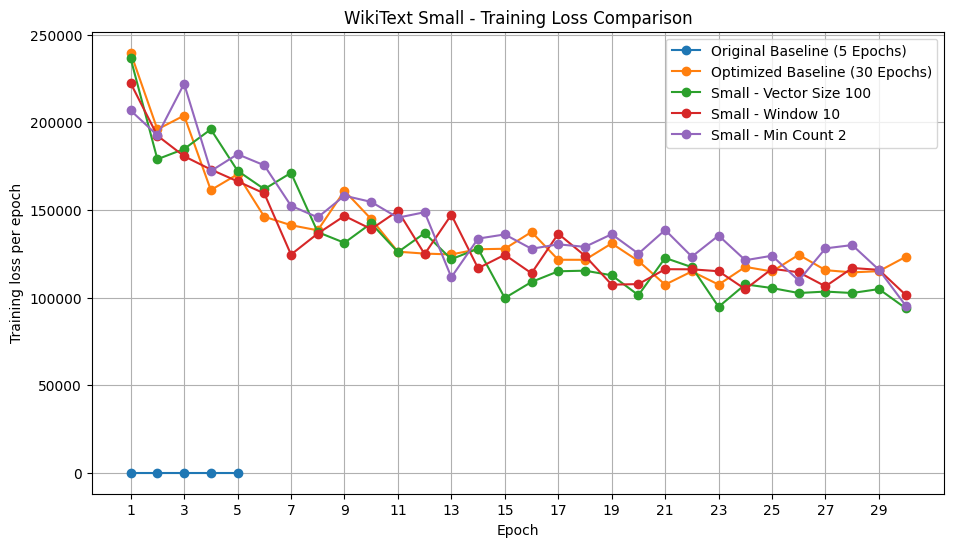

In [66]:
#results table
all_small_results = [
    small_baseline_results,
    optimized_baseline
] + small_hyperparameter_results


small_hyperparameter_df = pd.DataFrame(all_small_results)

columns = [
    "Model",
    "Epochs",
    "Vector Size",
    "Window",
    "Min Count",
    "Vocabulary Size",
    "Total Pairs",
    "Evaluated Pairs",
    "Missing Pairs",
    "Spearman Correlation",
    "P-value",
    "Coverage"
]

#display(small_hyperparameter_df[columns].round(4))
display(small_hyperparameter_df[columns])



all_small_loggers = {}

if "baseline_logger" in globals():
    all_small_loggers["Original Baseline (5 Epochs)"] = small_baseline_logger

all_small_loggers["Original Baseline (5 Epochs)"] = small_baseline_logger
all_small_loggers["Optimized Baseline (30 Epochs)"] = optimized_logger
all_small_loggers.update(small_hyperparameter_loggers)


#training loss curves
plt.figure(figsize=(11, 6))
for name, logger in all_small_loggers.items():
    plt.plot(
        range(1, len(logger.epoch_losses) + 1),
        logger.epoch_losses,
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("WikiText Small - Training Loss Comparison")
plt.xticks(range(1, 31, 2))
plt.legend()
plt.grid(True)


### 16. Hyperparameter Experiments — WikiText Large

The same three hyperparameter experiments are repeated using WikiText Large, with the selected training duration fixed at five epochs.

The experiments separately increase vector size to 100, increase context window to 10, and reduce min_count to 2.

Keeping the experimental configurations consistent across the two corpora allows us to investigate whether the same changes produce similar effects on semantic relatedness performance.

The results are compared with the WikiText Large baseline to identify which hyperparameter changes are beneficial.

In [68]:

#defining the three experiments
large_experiments = [
    {
        "name": "Large - Vector Size 100",
        "vector_size": 100,
        "window": 5,
        "min_count": 5
    },
    {
        "name": "Large - Window 10",
        "vector_size": 50,
        "window": 10,
        "min_count": 5
    },
    {
        "name": "Large - Min Count 2",
        "vector_size": 50,
        "window": 5,
        "min_count": 2
    }
]

large_hyperparameter_results = []
large_hyperparameter_loggers = {}

for experiment in large_experiments:

    print(f"\nTraining: {experiment['name']}")

    logger = EpochLossLogger()

    model = Word2Vec(
        sentences=large_corpus,
        vector_size=experiment["vector_size"],
        window=experiment["window"],
        min_count=experiment["min_count"],
        workers=8,
        epochs=5,
        sg=0,
        seed=42,
        compute_loss=True,
        callbacks=[logger]
    )

    #evaluate and retrieve the resulting dictionary
    results = evaluate_model(
        model,
        wordsim_data,
        experiment["name"]
    )

    large_hyperparameter_results.append(results)
    large_hyperparameter_loggers[experiment["name"]] = logger


Training: Large - Vector Size 100
Epoch 01 | epoch loss = 30958576.00 | cumulative loss = 30958576.00
Epoch 02 | epoch loss = 16178644.00 | cumulative loss = 47137220.00
Epoch 03 | epoch loss = 14505852.00 | cumulative loss = 61643072.00
Epoch 04 | epoch loss = 6850320.00 | cumulative loss = 68493392.00
Epoch 05 | epoch loss = 1979680.00 | cumulative loss = 70473072.00
Model: Large - Vector Size 100
Epochs: 5
Vector Size: 100
Window: 5
Min Count: 5
SG: 0
Workers: 8
Vocabulary Size: 171083
Total Pairs: 353
Evaluated Pairs: 353
Missing Pairs: 0
Spearman Correlation: 0.6537315585743501
P-value: 2.086990962593234e-44
Coverage: 100.0

Training: Large - Window 10
Epoch 01 | epoch loss = 27591168.00 | cumulative loss = 27591168.00
Epoch 02 | epoch loss = 15655580.00 | cumulative loss = 43246748.00
Epoch 03 | epoch loss = 12597976.00 | cumulative loss = 55844724.00
Epoch 04 | epoch loss = 11375508.00 | cumulative loss = 67220232.00
Epoch 05 | epoch loss = 1516800.00 | cumulative loss = 687370

In [ ]:
#results table
all_large_results = [
    #large_baseline_results,
] + large_hyperparameter_results


large_hyperparameter_df = pd.DataFrame(all_large_results)

columns = [
    "Model",
    "Epochs",
    "Vector Size",
    "Window",
    "Min Count",
    "Vocabulary Size",
    "Total Pairs",
    "Evaluated Pairs",
    "Missing Pairs",
    "Spearman Correlation",
    "P-value",
    "Coverage"
]

#display(large_hyperparameter_df[columns].round(4))
display(large_hyperparameter_df[columns])



all_large_loggers = {}

#all_large_loggers["Original Baseline (5 Epochs - Optimized)"] = large_baseline_logger
#all_large_loggers["Optimized Baseline (5 Epochs)"] = large_baseline_logger
all_large_loggers.update(large_hyperparameter_loggers)


#training loss curves
plt.figure(figsize=(11, 6))
for name, logger in all_large_loggers.items():
    plt.plot(
        range(1, len(logger.epoch_losses) + 1),
        logger.epoch_losses,
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("WikiText Large - Training Loss Comparison")
plt.xticks(range(1, 21, 2))
plt.legend()
plt.grid(True)


Increasing vector size from 50 to 100 improved Spearman correlation for both WikiText Small (0.3672 to 0.3944) and WikiText Large (0.6292 to 0.6461), suggesting that higher-dimensional embeddings can capture more information.

Increasing the context window from 5 to 10 produced the greatest improvement for both datasets, reaching 0.4027 and 0.6553 respectively. A wider window may capture broader associations between words.

Reducing min_count from 5 to 2 increased vocabulary coverage for WikiText Small from 73.94% to 87.82%, but its overall correlation decreased from 0.3672 to 0.3330. However, these correlations were calculated using different subsets of word pairs, limiting direct comparison. For WikiText Large, coverage remained at 100%, while correlation decreased from 0.6292 to 0.6201.

## Part II Questions & Answers

### e. What numbers did you use for wikitext_small and wikitext_large, and why?
For WikiText Small, we selected 30 epochs after testing 5, 10, 20, 30 and 40 epochs. Performance improved substantially up to 30 epochs, before decreasing at 40 epochs. Therefore, 30 epochs provided the best observed balance between semantic relatedness performance and training cost.

For WikiText Large, we selected 5 epochs after testing 5, 10 and 15 epochs. Increasing the number of epochs did not improve the observed Spearman correlation, making additional training unnecessary.

The training-loss curves generally decreased, but lower training loss did not always correspond to better WordSim-353 performance. This illustrates the importance of evaluating the learned representations rather than relying exclusively on training loss.

<br>

### f. Create a table of results that summarises your experiments. The table needs to have the following structure: every row should contain a different model (make sure you give it a meaningful name), and every column should contain the different hyperparameter values you changed for every run followed by the Spearman correlation coefficient and the coverage ratio.

The table is above this text block.

<br>

### g. Using the table of results from your answer to question g., write a short discussion section (max 200 words) that answers the following questions:

i. Does a bigger vocabulary yield better representations?

<br><br>

ii. Do bigger word vectors yield better representations?

<br><br>

iii. Does a bigger context window yield better representations?

<br><br>

iv. Step 6 requires you to look for the best combination of hyperparameters using the same two datasets for evaluation. Is this a good practice?

<br><br>

v. Different models may lead to different coverage ratios. Is this an issue, and if yes, why?

<br><br>